# Case study 1: APOGEE radial velocities for binary-star systems

This notebook produces figures and tables for Case study 1 of the paper. This demonstrates the basic `harv` pipeline applied to six APOGEE DR17 sources with different numbers of visits. For each source, we run the rejection sampler with a shared library of prior samples, compare the evidence for a companion against a constant-velocity model, and, when only a few samples survive, rerun the rejection sampling with ten times as many prior samples and continue with MCMC if the samples all lie in a single period mode.

The other notebook `select-apogee.ipynb` generates the visit velocities of the six sources to `../data/apogee/`. This notebook writes two figures (`../paper/figures/cs1-large-scatter.pdf` and `../paper/figures/cs1-small-scatter.pdf`) and the rows of the table (`../paper/tables/cs1-apogee-output.tex`).

In [1]:
import jax
import numpyro

# Enable float64 before importing harv:
jax.config.update("jax_enable_x64", True)
numpyro.set_host_device_count(4)

In [2]:
from pathlib import Path

import astropy.table as at
import harv
import harv.models as hm
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import numpyro.distributions as dist
from numpyro.diagnostics import print_summary
from unxt import Q

%matplotlib inline
print(f"harv {harv.__version__}, jax {jax.__version__}, numpyro {numpyro.__version__}")
print(jax.devices())

harv 0.0.2.dev258+g9eadbbfe8, jax 0.11.2, numpyro 0.22.0
[CpuDevice(id=0), CpuDevice(id=1), CpuDevice(id=2), CpuDevice(id=3)]


In [3]:
repo_path = Path("..").resolve()
data_path = repo_path / "data" / "apogee"
figure_path = repo_path / "paper" / "figures"
table_path = repo_path / "paper" / "tables"

figure_path.mkdir(exist_ok=True)
table_path.mkdir(exist_ok=True)

## Loading the data

`select-apogee.ipynb` writes one file per source, named by the bin in number of visits (`counts0`, `counts1`, `counts2`) and by whether the source is an obvious binary (`scatter0`) or unclear (`scatter1`). The uncertainties (`rv_err`) are already calibrated, so we use them as given. Sorting the file names orders the sources by the visit-count bin.

In [4]:
rv_data = {}
for path in sorted(data_path.glob("*.ecsv")):
    tbl = at.Table.read(path)
    rv_data[tbl.meta["APOGEE_ID"]] = harv.RVData(
        time=Q(tbl["jd"], "day"),
        rv=Q(tbl["rv"], "km/s"),
        rv_err=Q(tbl["rv_err"], "km/s"),
    )

assert len(rv_data) == 6
assert all(d.rv.value.dtype == np.float64 for d in rv_data.values())

## Prior and prior samples

The prior is uniform in $\ln P$ between 2 and 16,384 days, a normal distribution for the eccentricity with mean 0.5 and standard deviation 0.25 (truncated to $[0, 1)$), and uniform in the phase and argument of pericenter. The linear parameters have the default Gaussian priors: the scale of the prior on $K$ is $\sigma_{K,0} = 30~{\rm km~s^{-1}}$ at the default reference period of 1 yr, and $\sigma_{v_0} = 150~{\rm km~s^{-1}}$. We do not include a jitter parameter.

We draw $J = 10^7$ samples from this prior once and use them for all sources.

In [5]:
sigma_K0, sigma_v0 = 30.0, 150.0  # km/s
prior = hm.StandardRV().default_prior(
    period_min=Q(2.0, "day"),
    period_max=Q(16384.0, "day"),
    sigma_K0=Q(sigma_K0, "km/s"),
    sigma_v0=Q(sigma_v0, "km/s"),
    eccentricity=dist.TruncatedNormal(0.5, 0.25, low=0.0, high=1.0),
)
model = harv.RVModel()

J = 10_000_000
prior_samples = prior.sample(J, key=jax.random.key(0), model=model)
assert prior_samples["period"].value.dtype == np.float64

## Rejection sampling

We run the rejection sampler for each source with the same prior samples and request the evidence estimate. We also keep the log-likelihoods of the returned samples (`return_logprobs=True`) for the check below.

In [6]:
sampler = harv.RejectionSampler(prior, model)
samples = {}
for i, (apogee_id, data) in enumerate(rv_data.items()):
    samples[apogee_id] = sampler.run_with_samples(
        data,
        prior_samples,
        key=jax.random.key(i + 1),
        return_logprobs=True,
        return_evidence_stats=True,
    )

/var/folders/67/2zgxpmyd2z183j4k6r33nf740000gr/T/ipykernel_1356/269165552.py:4: UserWarning: Under-resolved rejection run: the evidence integral is dominated by ~2.0 effective prior sample(s) of 10000000 (below min_evidence_ess=3), so max_ln_likelihood=-21.4 may not have converged and the accepted-sample count (2) is not a reliable posterior size. Increase n_prior_samples (compare max_ln_likelihood across runs to check it stops rising) and/or continue with NumpyroSampler(prior, model).run(data, init_samples=...) to draw the posterior.
  samples[apogee_id] = sampler.run_with_samples(
/var/folders/67/2zgxpmyd2z183j4k6r33nf740000gr/T/ipykernel_1356/269165552.py:4: UserWarning: Under-resolved rejection run: the evidence integral is dominated by ~1.0 effective prior sample(s) of 10000000 (below min_evidence_ess=3), so max_ln_likelihood=-312.4 may not have converged and the accepted-sample count (1) is not a reliable posterior size. Increase n_prior_samples (compare max_ln_likelihood across 

## More prior samples for sources with few samples

When only a few samples survive, we rerun the rejection sampling with ten times as many new prior samples, $10J = 10^8$, and use this larger run in the rest of this notebook. If the largest marginal likelihood rises a lot, or the samples move to a different period, we note this.

In [7]:
for apogee_id, s in samples.items():
    if s.n_samples >= 256:
        continue
    more = sampler.run(
        rv_data[apogee_id],
        key=jax.random.key(10),
        n_prior_samples=10 * J,
        return_logprobs=True,
        return_evidence_stats=True,
    )
    P1, P2 = s["period"].to_value("day"), more["period"].to_value("day")
    print(
        f"{apogee_id}: max ln L {s.metadata['max_ln_likelihood']:.2f} -> "
        f"{more.metadata['max_ln_likelihood']:.2f}, M {s.n_samples} -> {more.n_samples}, "
        f"J_eff {s.metadata['ln_Z_int_ess']:.2g} -> {more.metadata['ln_Z_int_ess']:.2g}, "
        f"P {P1.min():.2f}-{P1.max():.2f} d -> {P2.min():.2f}-{P2.max():.2f} d"
    )
    samples[apogee_id] = more

/var/folders/67/2zgxpmyd2z183j4k6r33nf740000gr/T/ipykernel_1356/627057277.py:4: UserWarning: Under-resolved rejection run: the evidence integral is dominated by ~2.0 effective prior sample(s) of 100000000 (below min_evidence_ess=3), so max_ln_likelihood=-11.9 may not have converged and the accepted-sample count (2) is not a reliable posterior size. Increase n_prior_samples (compare max_ln_likelihood across runs to check it stops rising) and/or continue with NumpyroSampler(prior, model).run(data, init_samples=...) to draw the posterior.
  more = sampler.run(


2M15035796-4533457: max ln L -21.40 -> -11.90, M 2 -> 2, J_eff 2 -> 2, P 32.65-33.88 d -> 16.34-18.15 d
2M20183197+1953430: max ln L -312.41 -> -115.70, M 1 -> 1, J_eff 1 -> 1, P 55.24-55.24 d -> 51.29-51.29 d


/var/folders/67/2zgxpmyd2z183j4k6r33nf740000gr/T/ipykernel_1356/627057277.py:4: UserWarning: Under-resolved rejection run: the evidence integral is dominated by ~1.0 effective prior sample(s) of 100000000 (below min_evidence_ess=3), so max_ln_likelihood=-115.7 may not have converged and the accepted-sample count (1) is not a reliable posterior size. Increase n_prior_samples (compare max_ln_likelihood across runs to check it stops rising) and/or continue with NumpyroSampler(prior, model).run(data, init_samples=...) to draw the posterior.
  more = sampler.run(


## Constant-velocity model

For a constant-velocity model with the same prior on $v_0$, the marginal likelihood is a Gaussian with covariance $C + \sigma_{v_0}^2\,\mathbb{I}$, where $C$ is the (here, diagonal) covariance of the data. 

In [8]:
def ln_gaussian(data, extra_cov):
    y, err = data.rv.to_value("km/s"), data.rv_err.to_value("km/s")
    mvn = dist.MultivariateNormal(
        loc=jnp.zeros(len(y)), covariance_matrix=jnp.diag(err**2) + extra_cov
    )
    return mvn.log_prob(y)

## Results

For each source we record the number of surviving samples $S$, the effective sample size $J_{\rm eff}$, the largest importance weight $w_{\rm max} = \max_j L_j / \sum_j L_j$ (the returned `ln_Z_int` is $\ln \sum_j L_j / J$), and the log Bayes factor $\ln\mathcal{B}$ of the companion model relative to the constant-velocity model. For the sources with few samples, these come from the run with $10^8$ prior samples. If at least 256 samples survive (arbitrary threshold we set here), we keep the rejection samples; if fewer survive and they are unimodal in period, we continue with MCMC; otherwise the source needs more prior samples.

In [9]:
def outcome(s, data):
    if s.n_samples >= 256:
        return "rejection"
    return "MCMC" if s.period_unimodal(data) else "needs more prior samples"


rows = []
for apogee_id, s in samples.items():
    data, meta = rv_data[apogee_id], s.metadata
    rows.append(
        {
            "APOGEE_ID": apogee_id,
            "N": data.rv.shape[0],
            "T": np.ptp(data.time.to_value("day")),
            "M": s.n_samples,
            "J_eff": float(meta["ln_Z_int_ess"]),
            "J": meta["n_prior_samples"],
            "w_max": float(
                np.exp(meta["max_ln_likelihood"] - meta["ln_Z_int"])
                / meta["n_prior_samples"]
            ),
            "ln_B": float(meta["ln_Z_int"]) - ln_gaussian(data, sigma_v0**2),
            "ln_B_err": float(meta["ln_Z_int_mcse"]),
            "outcome": outcome(s, data),
        }
    )
results = at.Table(rows=rows)
results

APOGEE_ID,N,T,M,J_eff,J,w_max,ln_B,ln_B_err,outcome
str18,int64,float64,int64,float64,int64,float64,float64,float64,str24
2M15323868+4218297,3,25.97901999996975,9138,18396.83786373998,10000000,0.00010878162532347082,20401.34193622045,0.0073659464870841984,rejection
2M02323271+3350542,3,58.9921200000681,1353023,2754571.207044649,10000000,7.386290339605009e-07,2.453764796703629,0.0005128673411343812,rejection
2M15035796-4533457,6,1005.2495599999093,2,2.038912897133732,100000000,0.6764685009813568,55354.36998407402,0.7003266595265069,needs more prior samples
2M22122067+4152581,6,681.0901499995962,666393,1253501.4704611143,10000000,1.501390425244459e-06,3.0479421915131546,0.0008353234814378799,rejection
2M20183197+1953430,13,760.8871499998495,1,1.0,100000000,0.9999999999999947,97554.05950484797,0.9999999949999999,MCMC
2M16022747+2902099,12,2524.1811500000767,40352,205698.63900736877,10000000,2.4718639091900165e-05,21.986661978078324,0.002182081776010722,rejection


## Continuing with MCMC

For the source(s) with few, unimodal samples, we initialize 4 chains of NUTS from the rejection samples with {py:class}`~harv.NumpyroSampler`. We report $\hat{R}$ and the effective sample size from MCMC as well.

MCMC explores only the mode it starts in, so we also check the goodness of fit at the MAP sample: with calibrated uncertainties, $\chi^2$ should be close to the number of degrees of freedom, $N - 6$. 

In [10]:
mcmc = harv.NumpyroSampler(prior, model)
mcmc_samples = {}
for i, row in enumerate(results):
    if row["outcome"] != "MCMC":
        continue
    apogee_id = str(row["APOGEE_ID"])
    s = mcmc.run(
        rv_data[apogee_id],
        init_samples=samples[apogee_id],
        key=jax.random.key(100 + i),
        num_chains=4,
        num_warmup=1000,
        num_samples=2000,
        return_logprobs=True,
    )
    mcmc_samples[apogee_id] = s

    print(apogee_id)
    # wrap_angles makes K positive; Samples stores the chains one after another.
    w, names = s.wrap_angles(), [*s.nonlinear, *s.linear]
    print_summary({name: np.asarray(w[name].value).reshape(4, -1) for name in names})

    data, m = rv_data[apogee_id], s.map_sample()
    print(
        f"MAP sample: P = {m['period'].to_value('day').item():.4f} d, "
        f"ln L = {m.ln_likelihood.item():.2f}, "
        f"chi2 = {m.chi2(data, model).item():.1f}, "
        f"reduced chi2 = {m.reduced_chi2(data, model).item():.1f}, "
        "for {data.rv.shape[0]} visits"
    )

  0%|          | 0/3000 [00:00<?, ?it/s]

  0%|          | 0/3000 [00:00<?, ?it/s]

  0%|          | 0/3000 [00:00<?, ?it/s]

  0%|          | 0/3000 [00:00<?, ?it/s]

2M20183197+1953430

                    mean       std    median      5.0%     95.0%     n_eff     r_hat
        period     51.29      0.00     51.29     51.28     51.29   7945.21      1.00
  eccentricity      0.01      0.00      0.01      0.01      0.02   7756.58      1.00
    phase_peri      0.19      0.03      0.18      0.13      0.24   6490.25      1.00
      arg_peri      1.18      0.22      1.18      0.82      1.55   6493.00      1.00
    rv_semiamp     35.26      0.10     35.26     35.09     35.42   7474.78      1.00
         v_sys     -3.81      0.07     -3.81     -3.92     -3.69   8005.65      1.00

MAP sample: P = 51.2872 d, ln L = -5.37, chi2 = 2.7, reduced chi2 = 0.4, for {data.rv.shape[0]} visits


## Figure and table

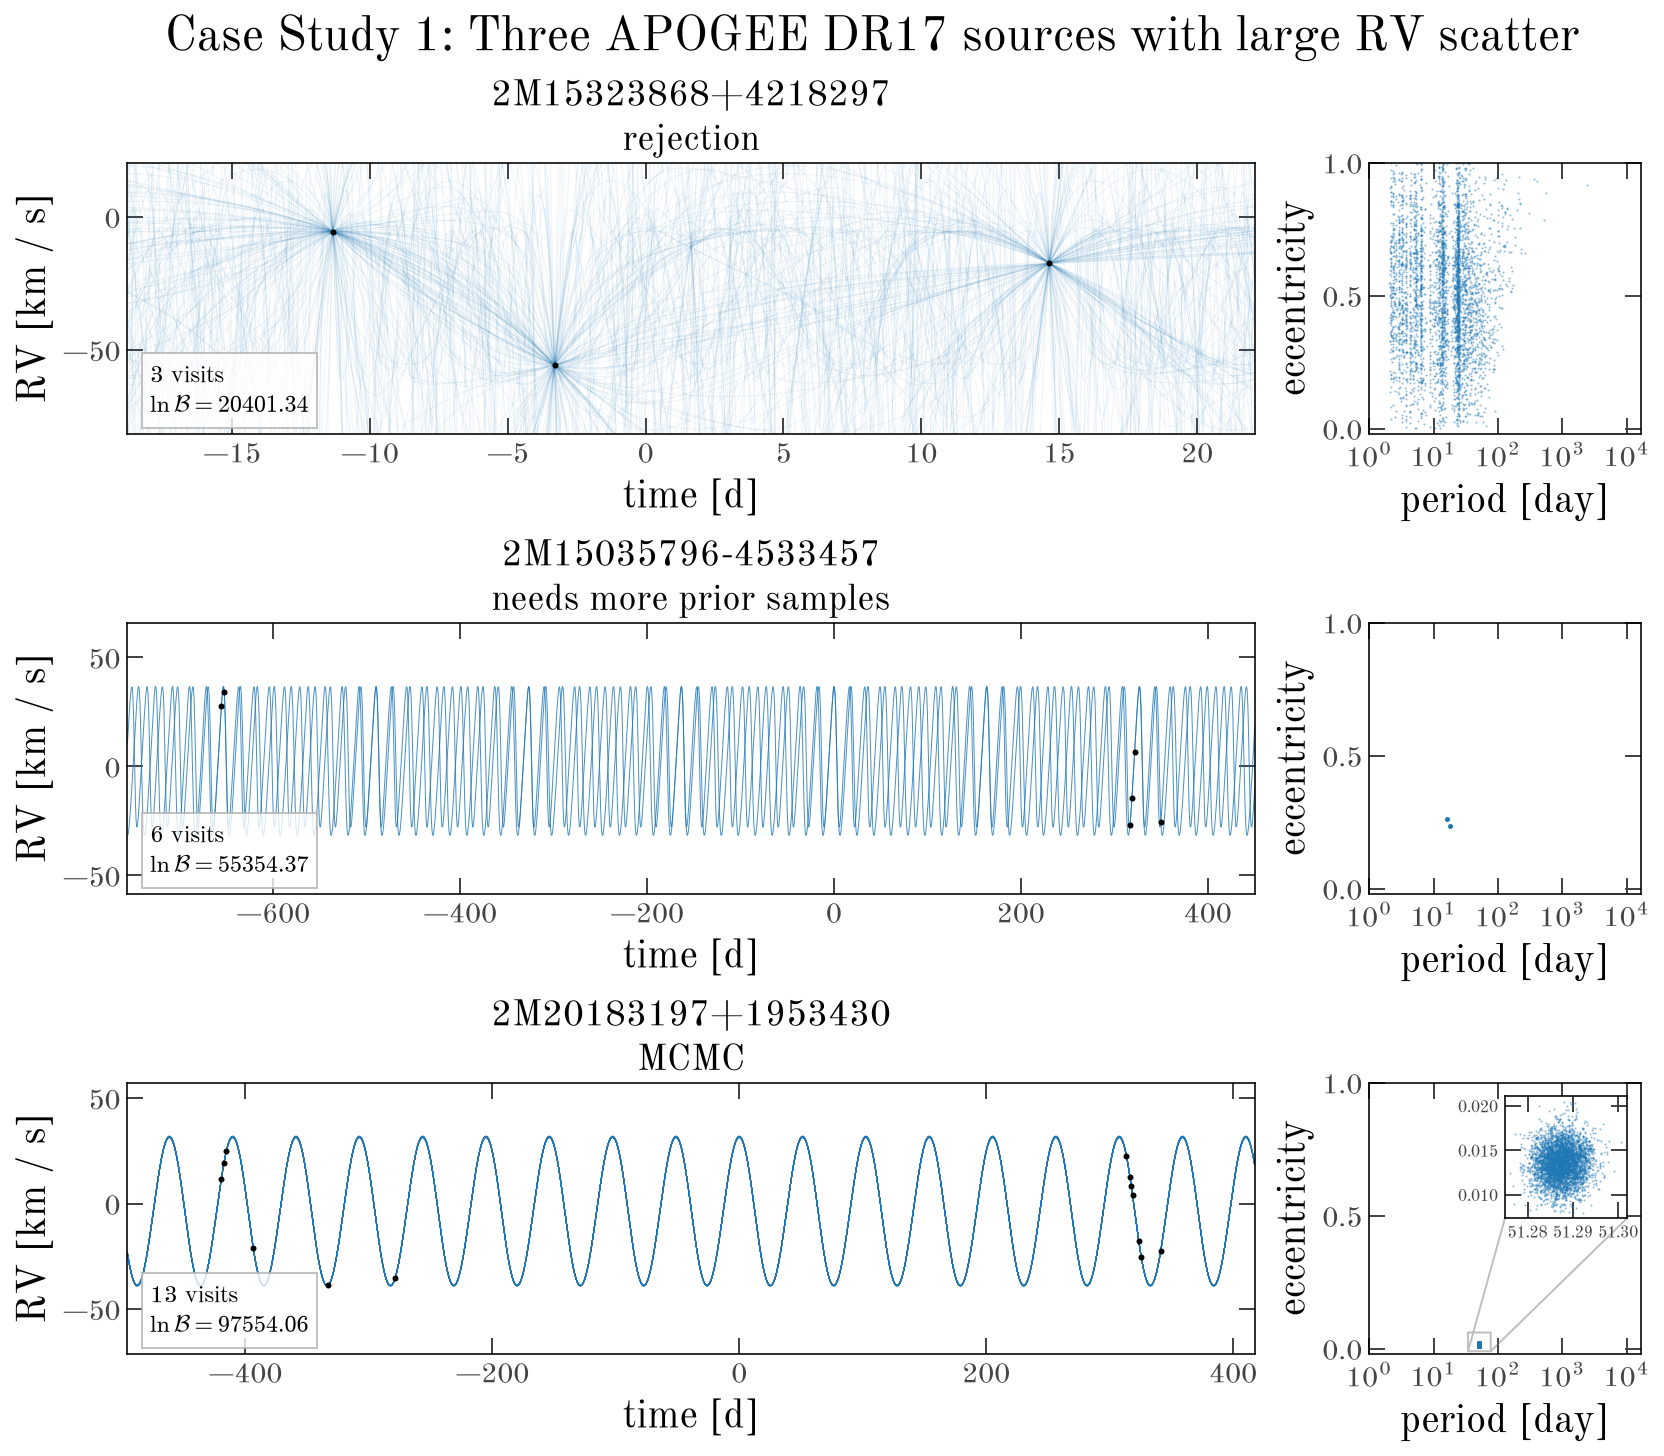

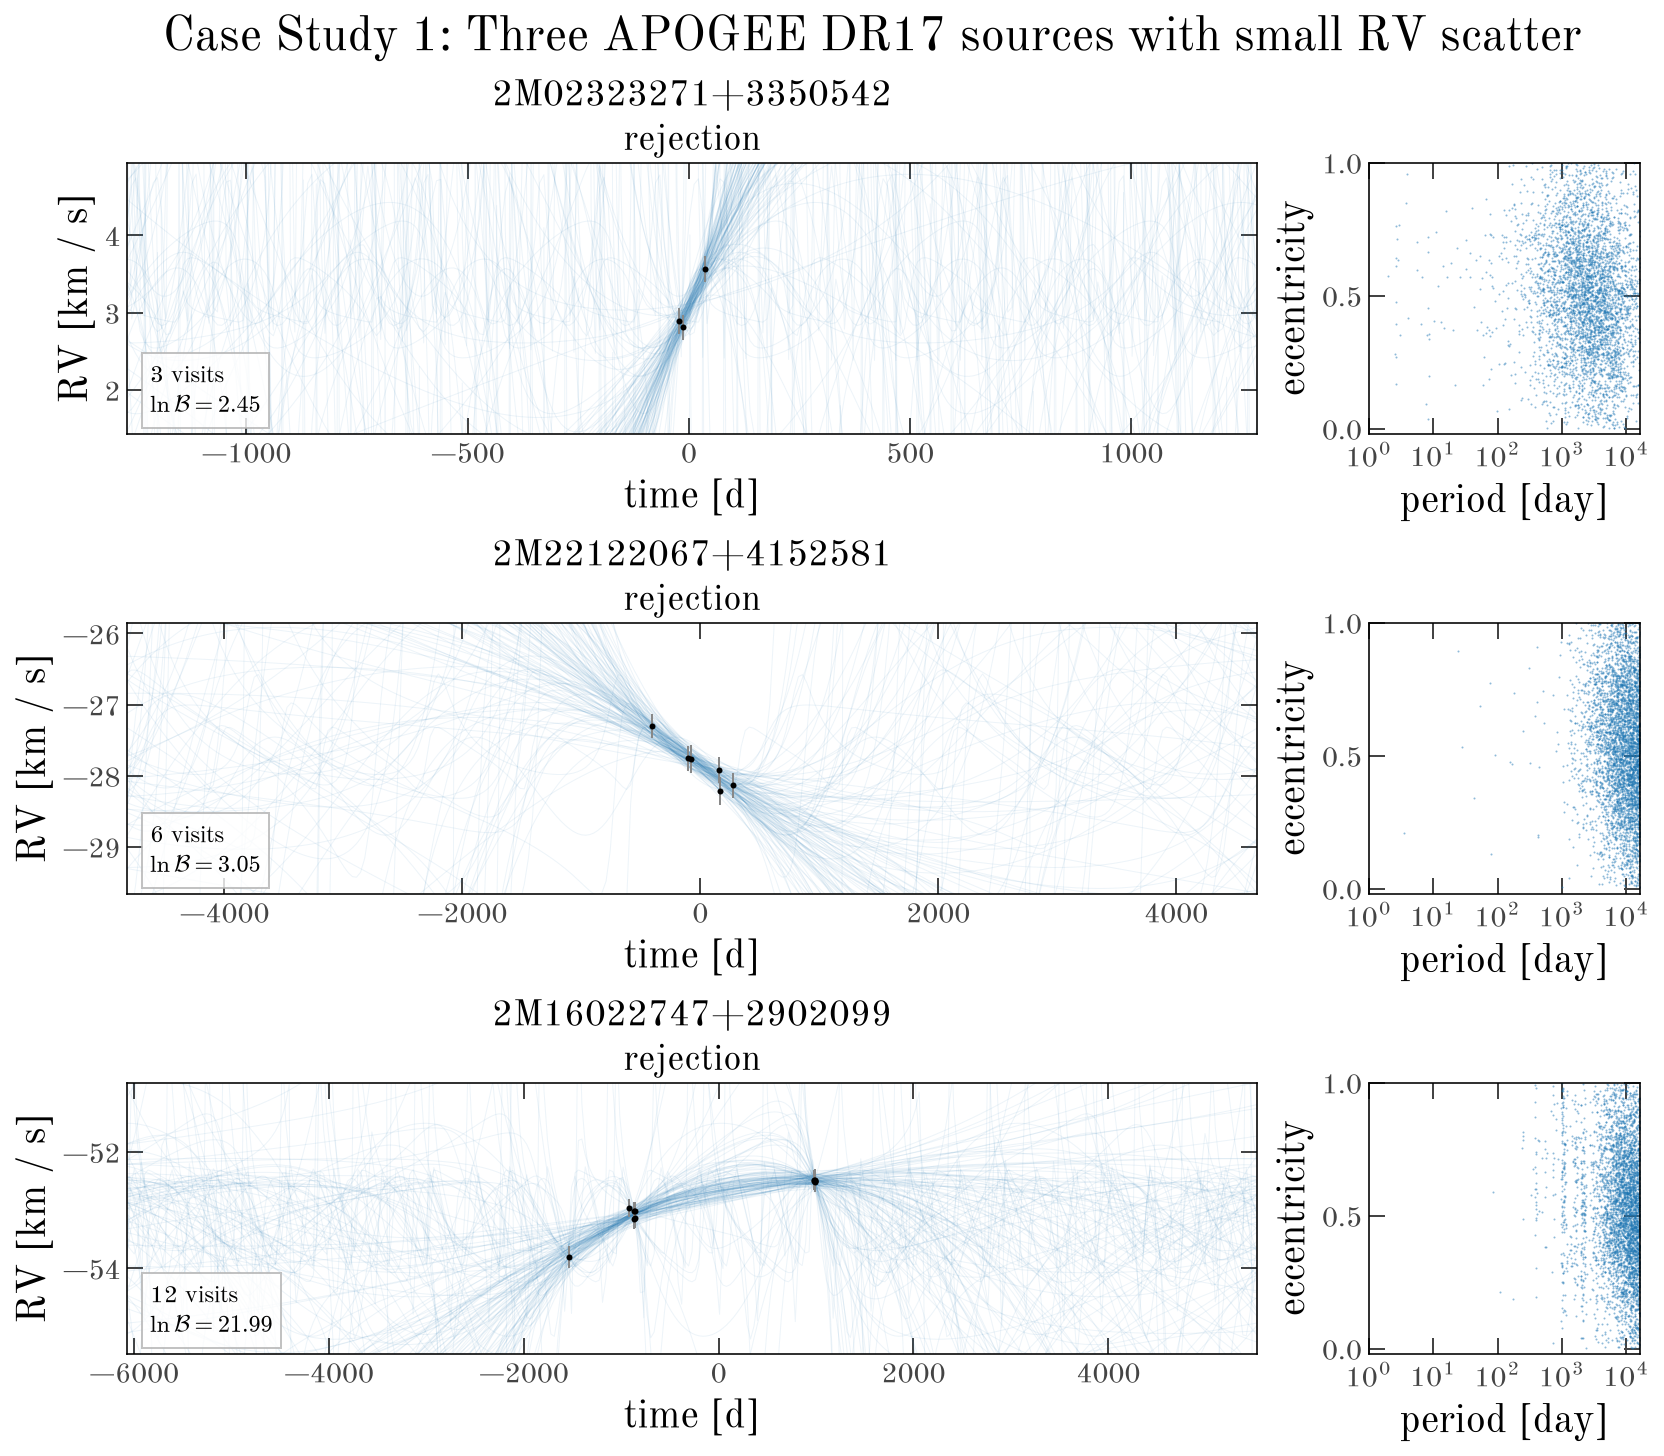

In [11]:
rng = np.random.default_rng(123)

# The data files alternate between large (scatter0) and small (scatter1) RV scatter.
for name, rows in [("large", results[0::2]), ("small", results[1::2])]:
    fig, axes = plt.subplots(
        3, 2, figsize=(12, 10), width_ratios=[2.5, 1], layout="constrained"
    )
    fig.suptitle(
        f"Case Study 1: Three APOGEE DR17 sources with {name} RV scatter", fontsize=24
    )

    for (ax_rv, ax_pe), row in zip(axes, rows, strict=True):
        apogee_id = row["APOGEE_ID"]
        data = rv_data[apogee_id]
        s = mcmc_samples.get(apogee_id, samples[apogee_id])

        # A random subset: plot_rv draws the first rows, and MCMC chains are stored in order.
        s = s[rng.choice(s.n_samples, min(s.n_samples, 4096), replace=False)]
        harv.plot.plot_rv(
            s, data=data, n_samples=128, relative_to_time_ref=True, ax=ax_rv
        )
        ax_rv.get_legend().remove()
        ax_rv.set_title(f"{apogee_id}\n{row['outcome']}", fontsize=18)
        ax_rv.autoscale(axis="x", tight=True)  # end at the orbit time grid
        ax_rv.text(
            0.02,
            0.05,
            f"{row['N']} visits\n$\\ln\\mathcal{{B}} = {row['ln_B']:.2f}$",
            transform=ax_rv.transAxes,
            va="bottom",
            fontsize=12,
            bbox={"facecolor": "w", "edgecolor": "0.7", "alpha": 0.8},
        )

        # Zoom to the data: with 3 visits, the posterior orbits reach hundreds of km/s.
        rv = data.rv.to_value("km/s")
        pad = 0.5 * np.ptp(rv) + 1
        ax_rv.set_ylim(rv.min() - pad, rv.max() + pad)

        ms = 2 if len(s) > 10 and np.std(s["period"].value) > 1.0 else 5
        alpha = 0.5 if len(s) > 100 else 1.0
        ax_pe.plot(
            s["period"].to_value("day"),
            s["eccentricity"].value,
            ".", ms=ms, mew=0, alpha=alpha, color="tab:blue", rasterized=True,
        )  # fmt: skip
        ax_pe.set(
            xscale="log",
            xlim=(2, 16384),
            ylim=(-0.02, 1),
            xlabel="period [day]",
            ylabel="eccentricity",
            xticks=10 ** np.arange(0, 4 + 1, 1),
        )
        ax_pe.set_box_aspect(1)

        # The MCMC posterior is a tiny mode: box it and zoom in with an inset.
        if row["outcome"] == "MCMC":
            P, e = s["period"].to_value("day"), s["eccentricity"].value
            axin = ax_pe.inset_axes([0.5, 0.5, 0.45, 0.45])
            axin.plot(
                P, e, ".", ms=2, mew=0, alpha=0.5, color="tab:blue", rasterized=True
            )
            axin.ticklabel_format(useOffset=False)
            axin.locator_params(nbins=3)
            axin.tick_params(labelsize=8)
            # The box is padded so it is visible at the scale of the full panel.
            x0, y0 = P.min() / 1.5, max(e.min() - 0.04, -0.01)
            ax_pe.indicate_inset(
                [x0, y0, 1.5 * P.max() - x0, e.max() + 0.04 - y0], inset_ax=axin
            )

    fig.savefig(figure_path / f"cs1-{name}-scatter.pdf", dpi=300)

In [12]:
tbl_filename = table_path / "cs1-apogee-output.tex"
with tbl_filename.open("w") as f:
    for r in results:
        # Dagger: J_eff < 3, so the evidence (and ln B) is unreliable and probably too low.
        dagger = "^\\dagger" if r["J_eff"] < 3 else ""
        f.write(
            f"{r['APOGEE_ID']} & {r['N']} & {r['T']:.0f} & \\num{{{r['M']}}} & "
            f"\\num{{{r['J_eff']:.3g}}} & "
            f"${r['ln_B']:.0f}{dagger}$ & {r['outcome']} \\\\\n"
        )
print(tbl_filename.read_text())

2M15323868+4218297 & 3 & 26 & \num{9138} & \num{1.84e+04} & $20401$ & rejection \\
2M02323271+3350542 & 3 & 59 & \num{1353023} & \num{2.75e+06} & $2$ & rejection \\
2M15035796-4533457 & 6 & 1005 & \num{2} & \num{2.04} & $55354^\dagger$ & needs more prior samples \\
2M22122067+4152581 & 6 & 681 & \num{666393} & \num{1.25e+06} & $3$ & rejection \\
2M20183197+1953430 & 13 & 761 & \num{1} & \num{1} & $97554^\dagger$ & MCMC \\
2M16022747+2902099 & 12 & 2524 & \num{40352} & \num{2.06e+05} & $22$ & rejection \\

